<a href="https://colab.research.google.com/github/J3remy1/east-river-water-quality/blob/main/01_salinity_by_group.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import pandas as pd

url = "https://raw.githubusercontent.com/J3remy1/east-river-water-quality/main/data/ditl_2026-10-06_east_river.csv"
df = pd.read_csv(url)
df.head()

,group,trial,salinity_time,salinity_ppt,water_temp_c,water_temp_f,ph,turbidity_cm,do_time,do_ppm,do_sat_reported
0,A,1,10:34,26.8,19,66,7.5,65.0,11:55,8.0,81.0
1,A,2,10:36,26.5,19,66,7.5,86.3,NaN,NaN,NaN
2,A,3,10:38,26.0,19,66,7.5,71.1,NaN,NaN,NaN
3,B,1,10:56,26.0,19,66,8.0,64.0,10:30,8.0,88.0
4,B,2,10:58,26.0,19,66,8.0,67.0,10:40,9.0,100.0


In [12]:
df.groupby("group")["salinity_ppt"].agg(["mean", "std", "count"])

,mean,std,count
group,,,
A,26.433333,0.404145,3
B,26.000000,0.000000,3
C,29.000000,0.000000,3
D,30.333333,4.932883,3
E,26.666667,1.527525,3
F,28.333333,0.577350,3


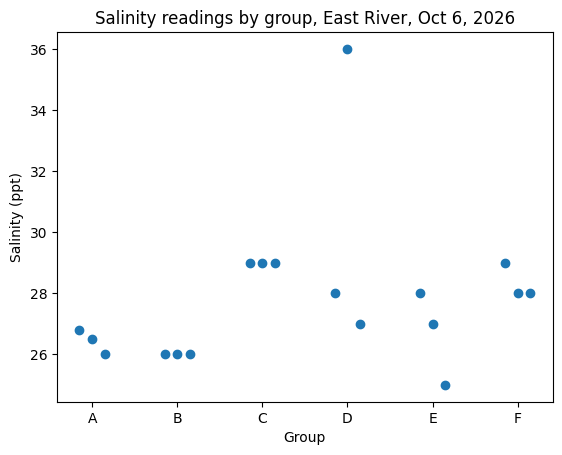

In [13]:
import matplotlib.pyplot as plt

x = df["group"].map({"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5})
x = x + (df["trial"] - 2) * 0.15

plt.scatter(x, df["salinity_ppt"])
plt.xticks([0, 1, 2, 3, 4, 5], ["A", "B", "C", "D", "E", "F"])
plt.xlabel("Group")
plt.ylabel("Salinity (ppt)")
plt.title("Salinity readings by group, East River, Oct 6, 2026")
plt.show()

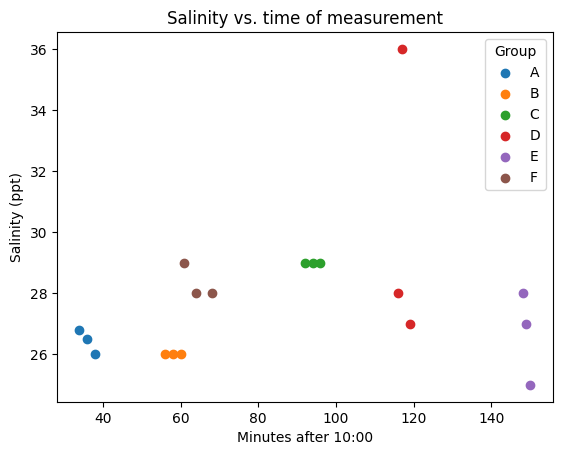

In [14]:
t = df["salinity_time"].str.split(":", expand=True).astype(int)
df["sal_min"] = (t[0] - 10) * 60 + t[1]

for g, sub in df.groupby("group"):
    plt.scatter(sub["sal_min"], sub["salinity_ppt"], label=g)

plt.legend(title="Group")
plt.xlabel("Minutes after 10:00")
plt.ylabel("Salinity (ppt)")
plt.title("Salinity vs. time of measurement")
plt.show()

## Findings: salinity
Within each group, most readings are close together, but the groups fall into two levels: about 26 ppt (A, B) and 28–29 ppt (C, F). Groups B and F measured salinity back to back (B: 10:56–11:00; F: 11:01–11:08), yet their readings differ by 2 to 3 ppt; this suggests that the gap comes from the meters or how they were read, not from the water itself. There is also an obvious outlier, 36 ppt, which is saltier than the open ocean (about 35 ppt) and far from the two other readings the same group took within three minutes (28 and 27). Some groups recorded the same value three times (B: 26; C: 29), which likely reflects the meter’s whole-number scale rather than perfect precision. With this data alone, measurement error cannot be separated from possible tidal change. Some values appear to be shared across groups and may not be independent measurements.